# New Zealand Electricity Generation Transition

### An Analysis of changes in the generation mix from 2010 to 2025. 

**Data source:** Ember Energy API  
**Country:** New Zealand  
**Time period:** January 2010 – December 2025  
**Time resolution:** Monthly

## 1. Project Overview

New Zealand's electricity system includes a combination of renewable and
fossil-fuel generation sources. Understanding how the generation mix has
changed over time can provide useful insight into the country's ongoing
electricity transition.

This project uses historical monthly electricity data retrieved directly
from the Ember Energy API to examine changes in New Zealand's electricity
generation mix between 2010 and 2025.

The analysis focuses on changes in:

- renewable electricity generation
- fossil-fuel generation
- individual generation sources such as hydro, wind, gas and coal
- total electricity generation
- the share of electricity generation provided by different sources

The results will be analysed using Python and presented through interactive
visualisations in Tableau.

## 2. Research Question

### Main Research Question

**How has New Zealand's electricity generation mix changed between 2010
and 2025?**

### Supporting Questions will be introduced later in the analysis



## 3. Data Source

Historical electricity-generation data for New Zealand was retrieved
directly from the Ember Energy API.

The API provides monthly electricity-generation data by generation source,
along with aggregate series such as renewable generation, fossil
generation, total generation and electricity demand.

The API response was returned in JSON format and will be converted into a
Pandas DataFrame for cleaning and analysis.

The study period requested through the API is January 2010 to December
2025. 

## Importing Libraries

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr


## Access Data from Ember API 

In [2]:


# Read the Ember API key from a separate local file
with open("EmberKey.txt", "r") as file:
    api_key = file.read().strip()

# Define the Ember API endpoint
url = "https://api.ember-energy.org/v1/electricity-generation/monthly"

# Set API query parameters
params = {
    "entity_code": "NZL",
    "start_date": "2010-01",
    "end_date": "2025-12",
    "api_key": api_key
}

# Send the API request
response = requests.get(
    url,
    params=params,
    timeout=30
)

# Check for HTTP errors
response.raise_for_status()

# Convert the response into JSON
data = response.json()

# Validate the API response structure
if "data" not in data:
    raise ValueError("The API response does not contain a 'data' field.")

print("API request successful.")
print("Number of records received:", len(data["data"]))


API request successful.
Number of records received: 2819


In [3]:
# Inspect the structure of the API response
data.keys()

dict_keys(['stats', 'data'])

## Convert API response to DataFrame

In [4]:
# Converting into DataFrame 
df = pd.DataFrame(data['data'])

## Initial Data Inspection

In [5]:
df.head()

,entity,entity_code,is_aggregate_entity,date,series,is_aggregate_series,generation_twh,share_of_generation_pct
0,New Zealand,NZL,False,2010-01-01,Bioenergy,False,0.02,0.71
1,New Zealand,NZL,False,2010-01-01,Clean,True,2.56,78.66
2,New Zealand,NZL,False,2010-01-01,Coal,False,0.21,6.50
3,New Zealand,NZL,False,2010-01-01,Demand,True,3.25,100.00
4,New Zealand,NZL,False,2010-01-01,Fossil,True,0.69,21.34


In [6]:
df.shape

(2819, 8)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2819 entries, 0 to 2818
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   entity                   2819 non-null   str    
 1   entity_code              2819 non-null   str    
 2   is_aggregate_entity      2819 non-null   bool   
 3   date                     2819 non-null   str    
 4   series                   2819 non-null   str    
 5   is_aggregate_series      2819 non-null   bool   
 6   generation_twh           2819 non-null   float64
 7   share_of_generation_pct  2819 non-null   float64
dtypes: bool(2), float64(2), str(4)
memory usage: 232.0 KB


In [8]:
df['series'].value_counts()

series
Bioenergy                                192
Clean                                    192
Demand                                   192
Fossil                                   192
Gas                                      192
Hydro                                    192
Hydro, bioenergy and other renewables    192
Other fossil                             192
Other renewables                         192
Renewables                               192
Total generation                         192
Wind                                     192
Wind and solar                           192
Coal                                     191
Solar                                    132
Name: count, dtype: int64

## Data Quality Check 

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
# Check for duplicate records for the same date and generation source
df.duplicated(subset=["date", "series"]).sum()

np.int64(0)

In [11]:
df.isna().sum()

entity                     0
entity_code                0
is_aggregate_entity        0
date                       0
series                     0
is_aggregate_series        0
generation_twh             0
share_of_generation_pct    0
dtype: int64

In [12]:
df[["series", "is_aggregate_series"]].sort_values('series')

,series,is_aggregate_series
0,Bioenergy,False
14,Bioenergy,False
28,Bioenergy,False
42,Bioenergy,False
56,Bioenergy,False
...,...,...
2758,Wind and solar,True
2773,Wind and solar,True
2788,Wind and solar,True
2803,Wind and solar,True


In [13]:
df.groupby("series")["date"].agg(["min", "max", "count"])

,min,max,count
series,,,
Bioenergy,2010-01-01,2025-12-01,192
Clean,2010-01-01,2025-12-01,192
Coal,2010-01-01,2025-12-01,191
Demand,2010-01-01,2025-12-01,192
Fossil,2010-01-01,2025-12-01,192
Gas,2010-01-01,2025-12-01,192
Hydro,2010-01-01,2025-12-01,192
"Hydro, bioenergy and other renewables",2010-01-01,2025-12-01,192
Other fossil,2010-01-01,2025-12-01,192


### Ember Electricity Generation Category Definitions - New Zealand.

| Main category         | Ember category       | What is included                                                                     |
| --------------------- | -------------------- | ------------------------------------------------------------------------------------ |
| **Clean / Renewable** | **Wind**             | Wind electricity generation                                                          |
| **Clean / Renewable** | **Solar**            | Solar electricity generation                                                         |
| **Clean / Renewable** | **Hydro**            | Hydroelectric electricity generation                                                 |
| **Clean / Renewable** | **Bioenergy**        | Electricity generated from bioenergy                                                 |
| **Clean / Renewable** | **Other Renewables** | **Geothermal, tidal and wave** electricity generation                                |
| **Fossil**            | **Coal**             | Coal-fired electricity generation                                                    |
| **Fossil**            | **Gas**              | Gas-fired electricity generation                                                     |
| **Fossil**            | **Other Fossil**     | **Oil and petroleum products, manufactured gases, and waste** electricity generation |


In [14]:
# Descriptive statistics for individual generation sources
df[df["is_aggregate_series"] == False].groupby("series")["generation_twh"].describe()

,count,mean,std,min,25%,50%,75%,max
series,,,,,,,,
Bioenergy,192.0,0.018073,0.006385,0.00,0.02,0.02,0.0200,0.03
Coal,191.0,0.137539,0.103353,0.00,0.05,0.12,0.1900,0.46
Gas,192.0,0.478281,0.185212,0.06,0.36,0.47,0.6000,0.93
Hydro,192.0,1.991615,0.227601,1.36,1.86,2.00,2.1325,2.51
Other fossil,192.0,0.000104,0.001443,0.00,0.00,0.00,0.0000,0.02
Other renewables,192.0,0.587812,0.091345,0.30,0.52,0.60,0.6400,0.85
Solar,132.0,0.019697,0.021858,0.00,0.01,0.01,0.0300,0.12
Wind,192.0,0.187083,0.067061,0.10,0.14,0.17,0.2100,0.44


In [15]:
expected_dates = pd.date_range(
    start="2010-01-01",
    end="2025-12-01",
    freq="MS"
)

coal_dates = df.loc[df["series"] == "Coal", "date"]

missing_coal_dates = expected_dates.difference(coal_dates)

missing_coal_dates

DatetimeIndex(['2010-01-01', '2010-02-01', '2010-03-01', '2010-04-01',
               '2010-05-01', '2010-06-01', '2010-07-01', '2010-08-01',
               '2010-09-01', '2010-10-01',
               ...
               '2025-03-01', '2025-04-01', '2025-05-01', '2025-06-01',
               '2025-07-01', '2025-08-01', '2025-09-01', '2025-10-01',
               '2025-11-01', '2025-12-01'],
              dtype='datetime64[us]', length=192, freq='MS')

In [16]:
df.loc[
    (df["date"] == "2020-09-01") &
    (df["series"].isin(["Coal", "Total generation", "Fossil"])),
    ["date", "series", "generation_twh"]
]

,date,series,generation_twh
1863,2020-09-01,Fossil,0.33
1871,2020-09-01,Total generation,3.07


In [17]:
df.loc[
    (df["date"] == "2020-09-01") &
    (df["series"].isin(["Coal", "Gas", "Other fossil"])),
    ["date", "series", "generation_twh"]
]

,date,series,generation_twh
1864,2020-09-01,Gas,0.33
1867,2020-09-01,Other fossil,0.00


In [18]:
df[df["is_aggregate_series"] == False].groupby("series")["generation_twh"].count()

series
Bioenergy           192
Coal                191
Gas                 192
Hydro               192
Other fossil        192
Other renewables    192
Solar               132
Wind                192
Name: generation_twh, dtype: int64

In [19]:
# Check date coverage and missing observations by source
df.groupby("series")["date"].agg(
    ["min", "max", "count"]
)

,min,max,count
series,,,
Bioenergy,2010-01-01,2025-12-01,192
Clean,2010-01-01,2025-12-01,192
Coal,2010-01-01,2025-12-01,191
Demand,2010-01-01,2025-12-01,192
Fossil,2010-01-01,2025-12-01,192
Gas,2010-01-01,2025-12-01,192
Hydro,2010-01-01,2025-12-01,192
"Hydro, bioenergy and other renewables",2010-01-01,2025-12-01,192
Other fossil,2010-01-01,2025-12-01,192


## Data Preparation

In [20]:
df["date"] = pd.to_datetime(df["date"])

In [21]:
df["year"] = df["date"].dt.year

In [22]:
df["date"].dtype

dtype('<M8[us]')

In [23]:
df["date"].head()

0   2010-01-01
1   2010-01-01
2   2010-01-01
3   2010-01-01
4   2010-01-01
Name: date, dtype: datetime64[us]

In [24]:
df[df["is_aggregate_series"] == False]["series"].unique()

<ArrowStringArray>
[       'Bioenergy',             'Coal',              'Gas',
            'Hydro',     'Other fossil', 'Other renewables',
             'Wind',            'Solar']
Length: 8, dtype: str

In [25]:
sources = df[df["is_aggregate_series"] == False].copy()

In [26]:
total_gen = df[df["series"] == "Total generation"].copy()

## Exploratory Data Analysis (EDA)

#### Question - How did different sources of New Zealand’s electricity generation change over the period from 2010 to 2025?

In [27]:
# Annual generation by different sources from 2010 to 2025.
annual_gen_by_sources = (sources
                       .groupby(['year','series'])['generation_twh']
                       .sum()
                       .reset_index()
                        )
annual_gen_by_sources

,year,series,generation_twh
0,2010,Bioenergy,0.24
1,2010,Coal,2.58
2,2010,Gas,7.92
3,2010,Hydro,23.99
4,2010,Other fossil,0.00
...,...,...,...
118,2025,Hydro,23.04
119,2025,Other fossil,0.00
120,2025,Other renewables,9.21
121,2025,Solar,0.81


In [28]:
annual_source_counts = (
    sources.groupby(["year", "series"])["generation_twh"]
    .count()
    .reset_index(name="months_available")
)

annual_source_counts.query(
    "series == 'Coal' and year == 2020"
)

,year,series,months_available
76,2020,Coal,11


**Data Quality Note – Missing Coal Observation**

The dataset contains one missing monthly observation for coal generation in September 2020. The annual Coal generation total for 2020 is therefore calculated using the 11 available monthly observations. The missing value was retained as missing (NaN) rather than replaced with zero or an estimated value.

Solar generation data begins in January 2015, resulting in 132 monthly observations over the study period. This reflects the available data coverage rather than an identified data-quality issue.

In [29]:
# Total generation by sources each year.
total_gen_yearly = (total_gen
             .groupby('year')['generation_twh']
             .sum()
            )
total_gen_yearly

year
2010    41.77
2011    41.38
2012    41.11
2013    40.30
2014    40.28
2015    40.81
2016    40.38
2017    40.81
2018    40.80
2019    41.15
2020    40.75
2021    41.18
2022    40.93
2023    40.93
2024    41.67
2025    41.57
Name: generation_twh, dtype: float64

In [30]:
annual_gen_share_pct = (
    annual_gen_by_sources["generation_twh"]
    / annual_gen_by_sources["year"].map(total_gen_yearly)
) * 100
annual_gen_share_pct 

0       0.574575
1       6.176682
2      18.960977
3      57.433565
4       0.000000
         ...    
118    55.424585
119     0.000000
120    22.155401
121     1.948521
122     8.828482
Length: 123, dtype: float64

In [31]:
annual_gen_summary = annual_gen_by_sources.copy()

annual_gen_summary["total_generation_twh"] = (
    annual_gen_summary["year"].map(total_gen_yearly)
)

annual_gen_summary["annual_share_pct"] = annual_gen_share_pct

In [32]:
annual_gen_summary.head()

,year,series,generation_twh,total_generation_twh,annual_share_pct
0,2010,Bioenergy,0.24,41.77,0.574575
1,2010,Coal,2.58,41.77,6.176682
2,2010,Gas,7.92,41.77,18.960977
3,2010,Hydro,23.99,41.77,57.433565
4,2010,Other fossil,0.00,41.77,0.000000


In [33]:
source_wide = annual_gen_summary.pivot(
    index="year",
    columns="series",
    values="generation_twh"
)

In [34]:
source_wide.head()

series,Bioenergy,Coal,Gas,Hydro,Other fossil,Other renewables,Solar,Wind
year,,,,,,,,
2010,0.24,2.58,7.92,23.99,0.0,5.38,NaN,1.60
2011,0.24,1.84,7.48,24.34,0.0,5.64,NaN,1.81
2012,0.23,2.91,8.20,22.12,0.0,5.75,NaN,1.90
2013,0.27,2.01,7.84,22.38,0.0,5.93,NaN,1.89
2014,0.25,1.34,6.45,23.62,0.0,6.64,NaN,1.94


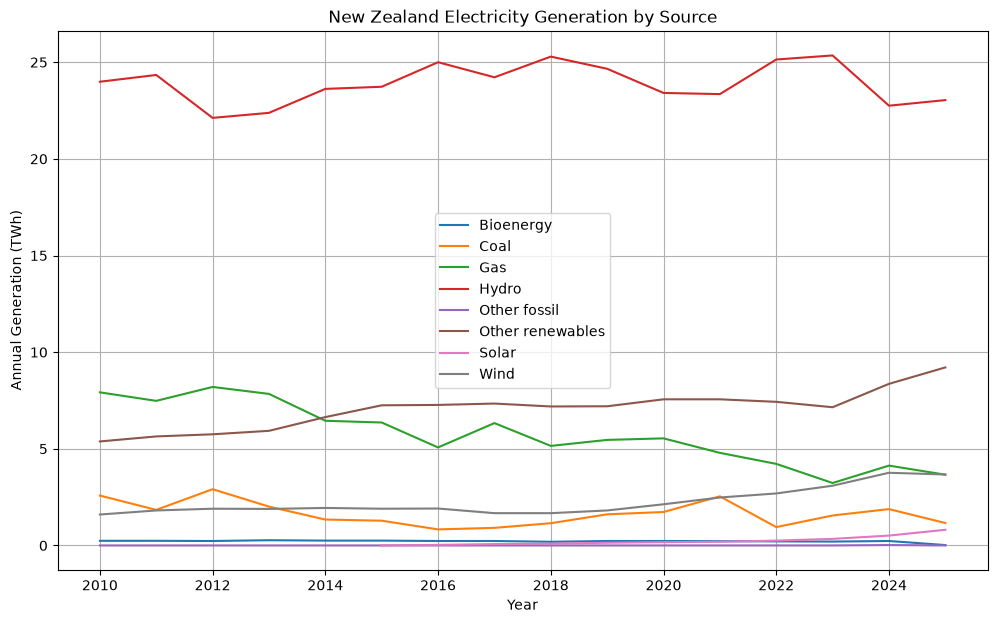

In [35]:
plt.figure(figsize=(12, 7))

for source in source_wide.columns:
    plt.plot(
        source_wide.index,
        source_wide[source],
        label=source
    )

plt.xlabel("Year")
plt.ylabel("Annual Generation (TWh)")
plt.title("New Zealand Electricity Generation by Source")
plt.legend()
plt.grid(True)
plt.show()

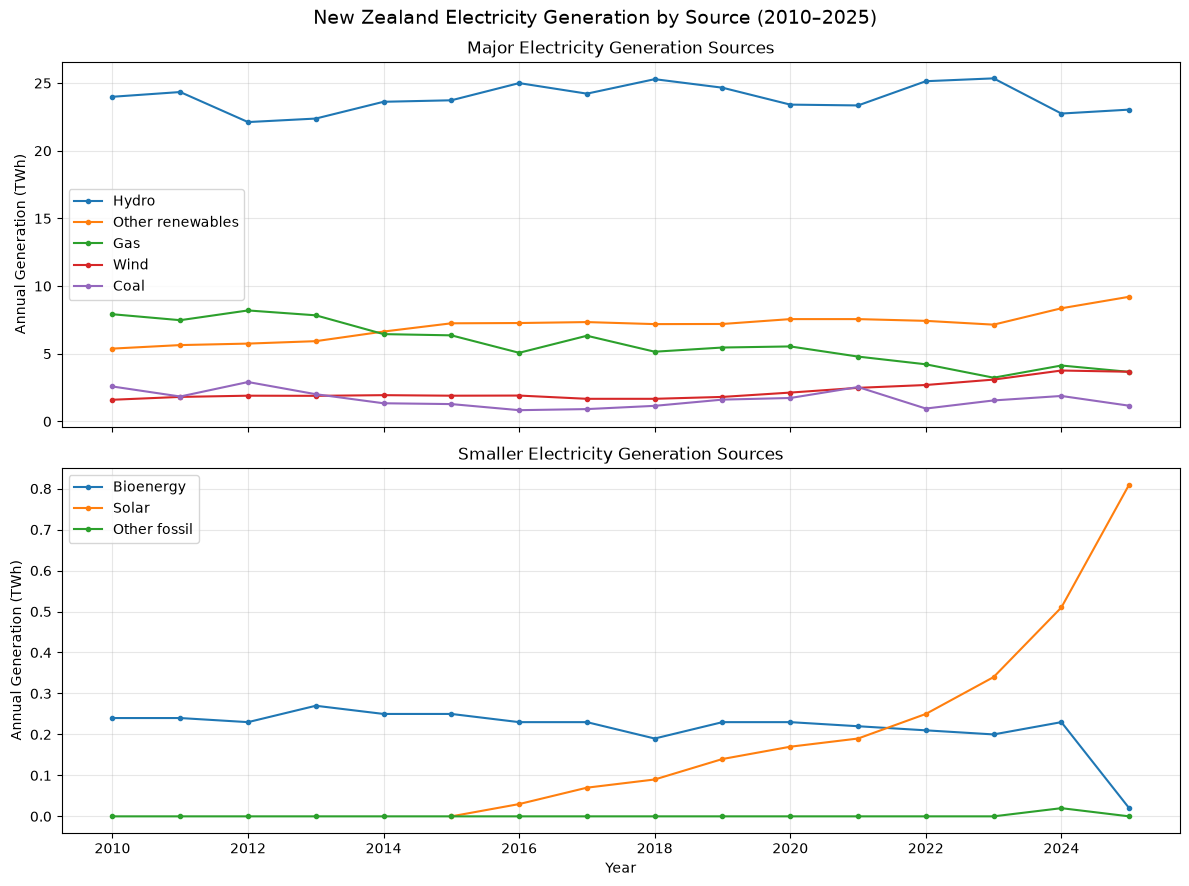

In [36]:

# Split generation sources into major and smaller sources
major_sources = [
    "Hydro",
    "Other renewables",
    "Gas",
    "Wind",
    "Coal"
]

smaller_sources = [
    "Bioenergy",
    "Solar",
    "Other fossil"
]

# Create two plots with a shared x-axis
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 9),
    sharex=True
)

# Plot 1: Major generation sources
for source in major_sources:
    axes[0].plot(
        source_wide.index,
        source_wide[source],
        marker="o",
        markersize=3,
        label=source
    )

axes[0].set_title("Major Electricity Generation Sources")
axes[0].set_ylabel("Annual Generation (TWh)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)


# Plot 2: Smaller generation sources
for source in smaller_sources:
    axes[1].plot(
        source_wide.index,
        source_wide[source],
        marker="o",
        markersize=3,
        label=source
    )

axes[1].set_title("Smaller Electricity Generation Sources")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Annual Generation (TWh)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

fig.suptitle(
    "New Zealand Electricity Generation by Source (2010–2025)",
    fontsize=14
)

plt.tight_layout()
plt.show()


#### Question - How did renewable and fossil fuel electricity generation change over time from 2010 to 2025

In [37]:
Categories = df[df["series"].isin(
    ["Renewables", "Fossil", "Total generation"]
)].copy()

Categories = (
    Categories
    .groupby(["year", "series"])["generation_twh"]
    .sum()
    .reset_index()
)
Categories

,year,series,generation_twh
0,2010,Fossil,10.52
1,2010,Renewables,31.24
2,2010,Total generation,41.77
3,2011,Fossil,9.33
4,2011,Renewables,32.06
5,2011,Total generation,41.38
6,2012,Fossil,11.09
7,2012,Renewables,30.01
8,2012,Total generation,41.11
9,2013,Fossil,9.86


In [38]:
categories_wide = Categories.pivot(
    index="year",
    columns="series",
    values="generation_twh"
)

In [39]:
categories_wide

series,Fossil,Renewables,Total generation
year,,,
2010,10.52,31.24,41.77
2011,9.33,32.06,41.38
2012,11.09,30.01,41.11
2013,9.86,30.45,40.30
2014,7.80,32.49,40.28
2015,7.64,33.21,40.81
2016,5.91,34.49,40.38
2017,7.26,33.58,40.81
2018,6.33,34.47,40.80


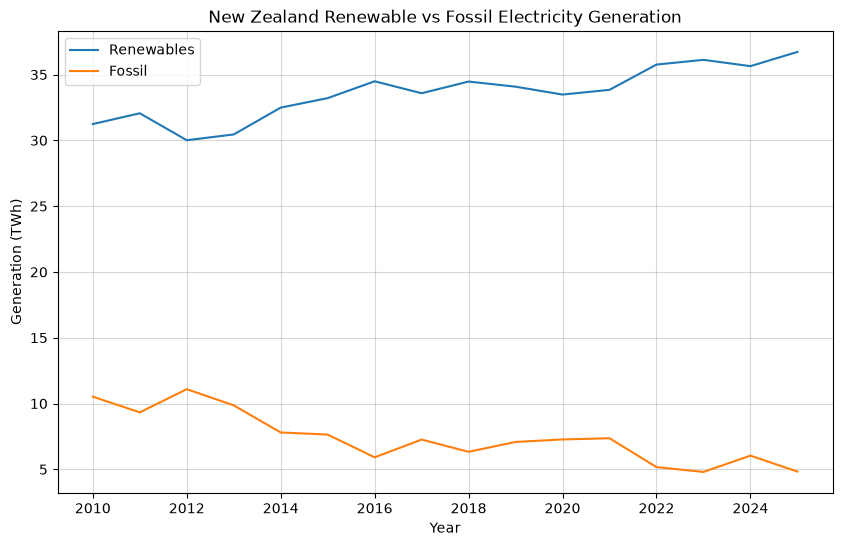

In [40]:
plt.figure(figsize=(10, 6))

plt.plot(
    categories_wide.index,
    categories_wide[["Renewables", "Fossil"]]
)
plt.xlabel("Year")
plt.ylabel("Generation (TWh)")
plt.title("New Zealand Renewable vs Fossil Electricity Generation")
plt.legend(["Renewables","Fossil"])
plt.grid(True, alpha =0.5)

plt.show()

In [41]:
from scipy.stats import pearsonr
correlation, p_value = pearsonr(
    categories_wide["Renewables"],
    categories_wide["Fossil"]
)

print("Pearson correlation:", correlation)
print("p-value:", p_value)

Pearson correlation: -0.9736284836578766
p-value: 2.2184938814757685e-10


The Pearson correlation coefficient (r = −0.974) indicates a very strong negative linear association between renewable and fossil electricity generation over the period 2010–2025. This suggests that years with higher renewable generation generally correspond to lower fossil-fuel generation.

The calculated p-value (2.22 × 10⁻¹⁰) is very small. However, this result should be interpreted cautiously because the analysis uses only 16 annual observations, and the two generation categories are components of total electricity generation. Possible time-series dependence may also influence the result. Therefore, the correlation is treated as descriptive evidence of an association rather than proof of an independent or causal relationship.

#### Question -How did each source of electricity generation differ between 2010 and 2025?

In [42]:
generation_change = pd.DataFrame({
    "2010_generation_twh": source_wide.loc[2010],
    "2025_generation_twh": source_wide.loc[2025]
})

In [43]:
generation_change["change_twh"] = (
    generation_change["2025_generation_twh"]
    - generation_change["2010_generation_twh"]
)

In [44]:
generation_change

,2010_generation_twh,2025_generation_twh,change_twh
series,,,
Bioenergy,0.24,0.02,-0.22
Coal,2.58,1.16,-1.42
Gas,7.92,3.66,-4.26
Hydro,23.99,23.04,-0.95
Other fossil,0.00,0.00,0.00
Other renewables,5.38,9.21,3.83
Solar,NaN,0.81,NaN
Wind,1.60,3.67,2.07


In [45]:
generation_change.sort_values("change_twh", ascending=False)

,2010_generation_twh,2025_generation_twh,change_twh
series,,,
Other renewables,5.38,9.21,3.83
Wind,1.60,3.67,2.07
Other fossil,0.00,0.00,0.00
Bioenergy,0.24,0.02,-0.22
Hydro,23.99,23.04,-0.95
Coal,2.58,1.16,-1.42
Gas,7.92,3.66,-4.26
Solar,NaN,0.81,NaN


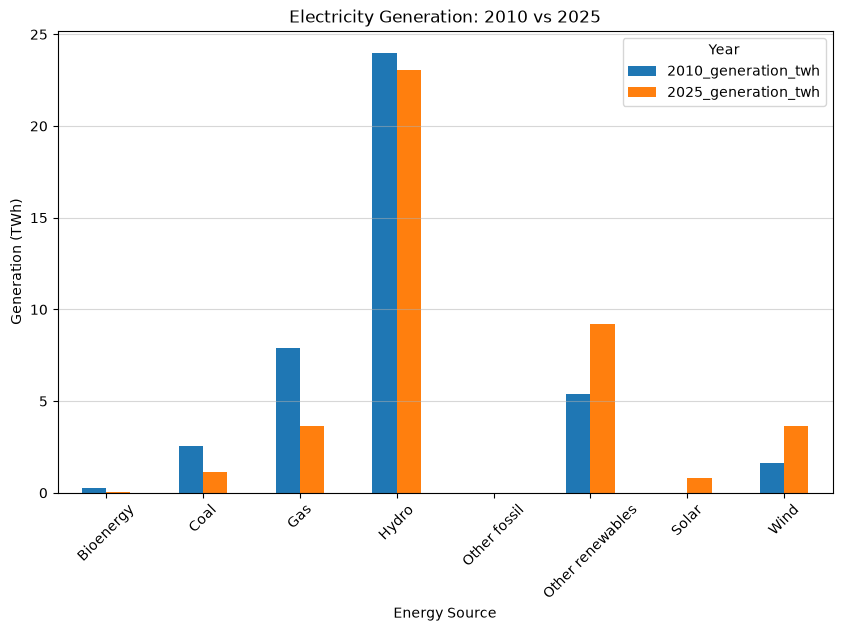

In [46]:
generation_change[["2010_generation_twh", "2025_generation_twh"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.xlabel("Energy Source")
plt.ylabel("Generation (TWh)")
plt.title("Electricity Generation: 2010 vs 2025")
plt.xticks(rotation=45)
plt.legend(title="Year")
plt.grid(axis="y", alpha=0.5)

plt.show()

#### Question What is the overall change in electricity generation by each source between 2010 and 2025—and did each source increase or decrease?”

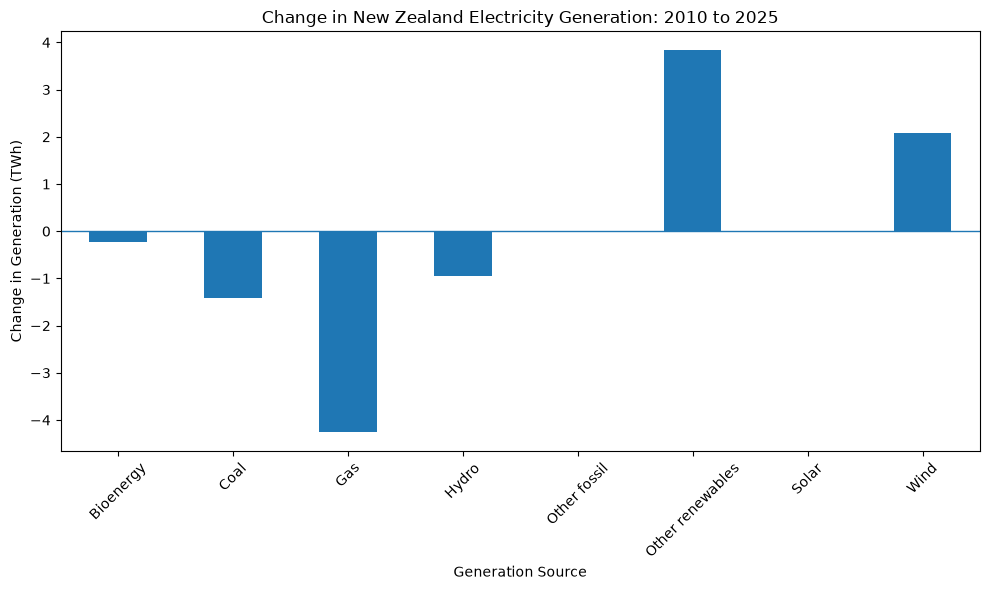

In [47]:
generation_change["change_twh"].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.xlabel("Generation Source")
plt.ylabel("Change in Generation (TWh)")
plt.title("Change in New Zealand Electricity Generation: 2010 to 2025")
plt.xticks(rotation=45)
plt.axhline(0, linewidth=1)
plt.tight_layout()
plt.show()

#### Question How did the share of each source in New Zealand’s total electricity generation change between 2010 and 2025

In [48]:
share_change = annual_gen_summary[
    annual_gen_summary["year"].isin([2010, 2025])
].pivot(
    index="series",
    columns="year",
    values="annual_share_pct"
)

share_change

year,2010,2025
series,,
Bioenergy,0.574575,0.048112
Coal,6.176682,2.790474
Gas,18.960977,8.804426
Hydro,57.433565,55.424585
Other fossil,0.000000,0.000000
Other renewables,12.880057,22.155401
Solar,NaN,1.948521
Wind,3.830500,8.828482


In [49]:
share_change["change_percentage_points"] = (
    share_change[2025] - share_change[2010]
)

share_change.sort_values(
    "change_percentage_points",
    ascending=False
)

year,2010,2025,change_percentage_points
series,,,
Other renewables,12.880057,22.155401,9.275343
Wind,3.830500,8.828482,4.997982
Other fossil,0.000000,0.000000,0.000000
Bioenergy,0.574575,0.048112,-0.526463
Hydro,57.433565,55.424585,-2.008980
Coal,6.176682,2.790474,-3.386208
Gas,18.960977,8.804426,-10.156551
Solar,NaN,1.948521,NaN


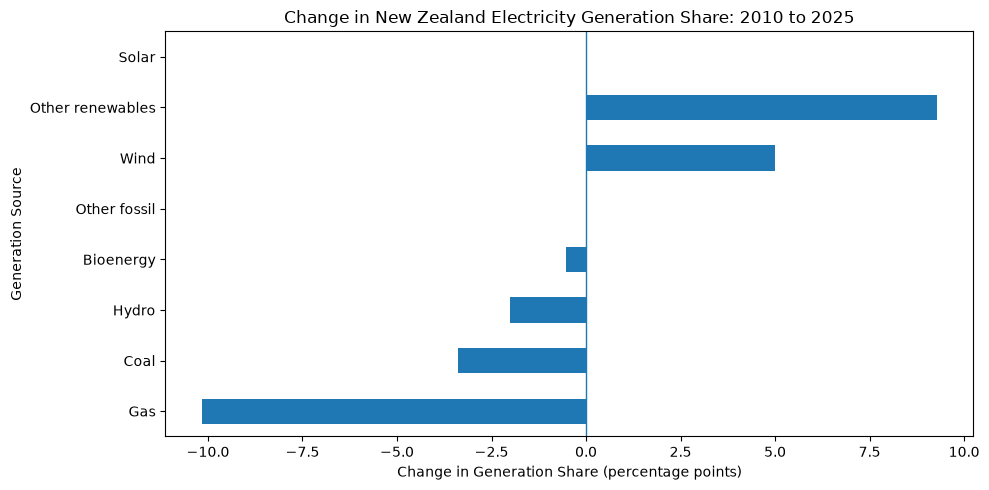

In [50]:
plt.figure(figsize=(10, 5))

share_change["change_percentage_points"].sort_values().plot(
    kind="barh"
)

plt.xlabel("Change in Generation Share (percentage points)")
plt.ylabel("Generation Source")
plt.title("Change in New Zealand Electricity Generation Share: 2010 to 2025")
plt.axvline(0, linewidth=1)
plt.tight_layout()
plt.show()

#### Question How did the share of renewable electricity in New Zealand’s total generation evolve from 2010 to 2025?”

In [51]:
categories_wide["renewable_share_pct"] = (
    categories_wide["Renewables"]
    / categories_wide["Total generation"]
) * 100

In [52]:
categories_wide[["Renewables", "Total generation", "renewable_share_pct"]].head()

series,Renewables,Total generation,renewable_share_pct
year,,,
2010,31.24,41.77,74.790520
2011,32.06,41.38,77.477042
2012,30.01,41.11,72.999270
2013,30.45,40.30,75.558313
2014,32.49,40.28,80.660377


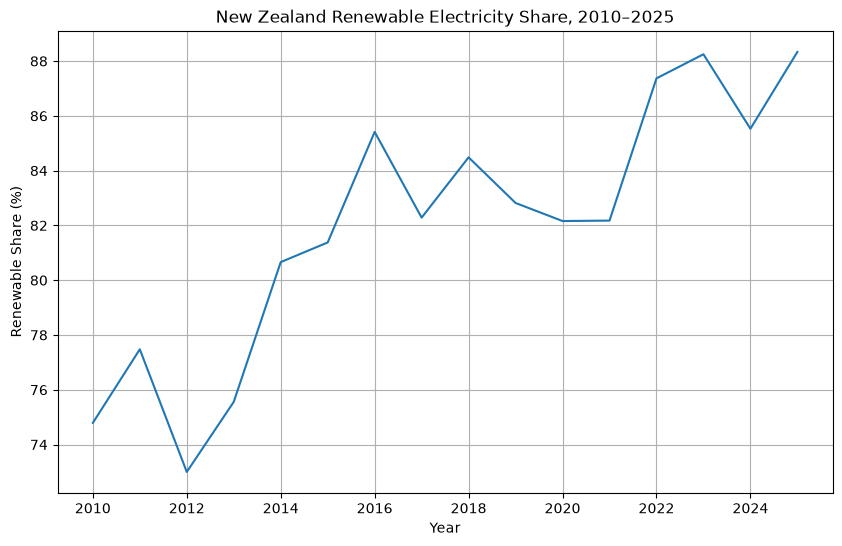

In [53]:
plt.figure(figsize=(10, 6))

plt.plot(
    categories_wide.index,
    categories_wide["renewable_share_pct"]
)

plt.xlabel("Year")
plt.ylabel("Renewable Share (%)")
plt.title("New Zealand Renewable Electricity Share, 2010–2025")
plt.grid(True)
plt.show()

##### Just Verifying that the sum of renewable and fossil electricity generation matches total generation.

In [54]:
categories_wide["check"] = (
    categories_wide["Renewables"]
    + categories_wide["Fossil"]
    - categories_wide["Total generation"]
)

categories_wide[["Renewables", "Fossil", "Total generation", "check"]].head()

series,Renewables,Fossil,Total generation,check
year,,,,
2010,31.24,10.52,41.77,-0.01
2011,32.06,9.33,41.38,0.01
2012,30.01,11.09,41.11,-0.01
2013,30.45,9.86,40.30,0.01
2014,32.49,7.80,40.28,0.01


In [55]:
categories_wide["check"].abs().max()

np.float64(0.03999999999999915)

#### Question How does the composition of New Zealand’s electricity generation mix change across sources from 2010 to 2025

<Figure size 1200x700 with 0 Axes>

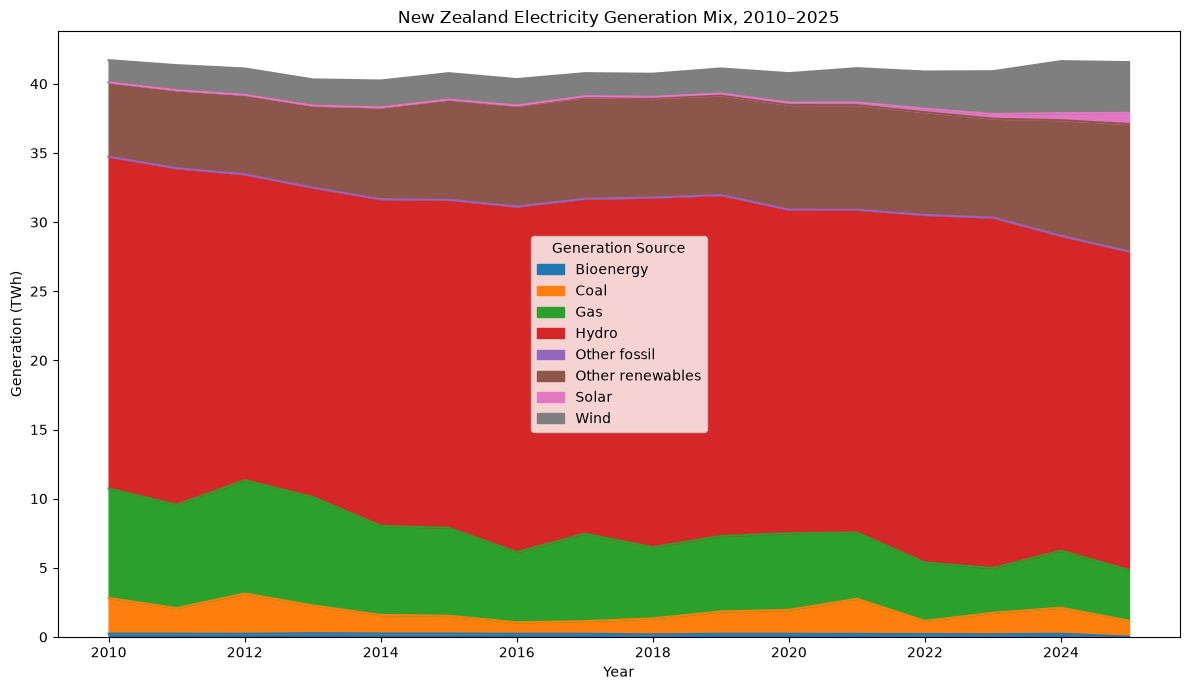

In [56]:
plt.figure(figsize=(12, 7))

source_wide.plot(
    kind="area",
    stacked=True,
    figsize=(12, 7)
)

plt.xlabel("Year")
plt.ylabel("Generation (TWh)")
plt.title("New Zealand Electricity Generation Mix, 2010–2025")
plt.legend(title="Generation Source")
plt.tight_layout()
plt.show()

#### Question How does the composition of New Zealand’s electricity generation share mix change across sources from 2010 to 2025

In [57]:
source_share_wide = annual_gen_summary.pivot(
    index="year",
    columns="series",
    values="annual_share_pct"
)

In [58]:
source_share_wide.head()

series,Bioenergy,Coal,Gas,Hydro,Other fossil,Other renewables,Solar,Wind
year,,,,,,,,
2010,0.574575,6.176682,18.960977,57.433565,0.0,12.880057,NaN,3.830500
2011,0.579990,4.446593,18.076365,58.820686,0.0,13.629773,NaN,4.374094
2012,0.559475,7.078570,19.946485,53.806860,0.0,13.986865,NaN,4.621747
2013,0.669975,4.987593,19.454094,55.533499,0.0,14.714640,NaN,4.689826
2014,0.620655,3.326713,16.012910,58.639523,0.0,16.484608,NaN,4.816286


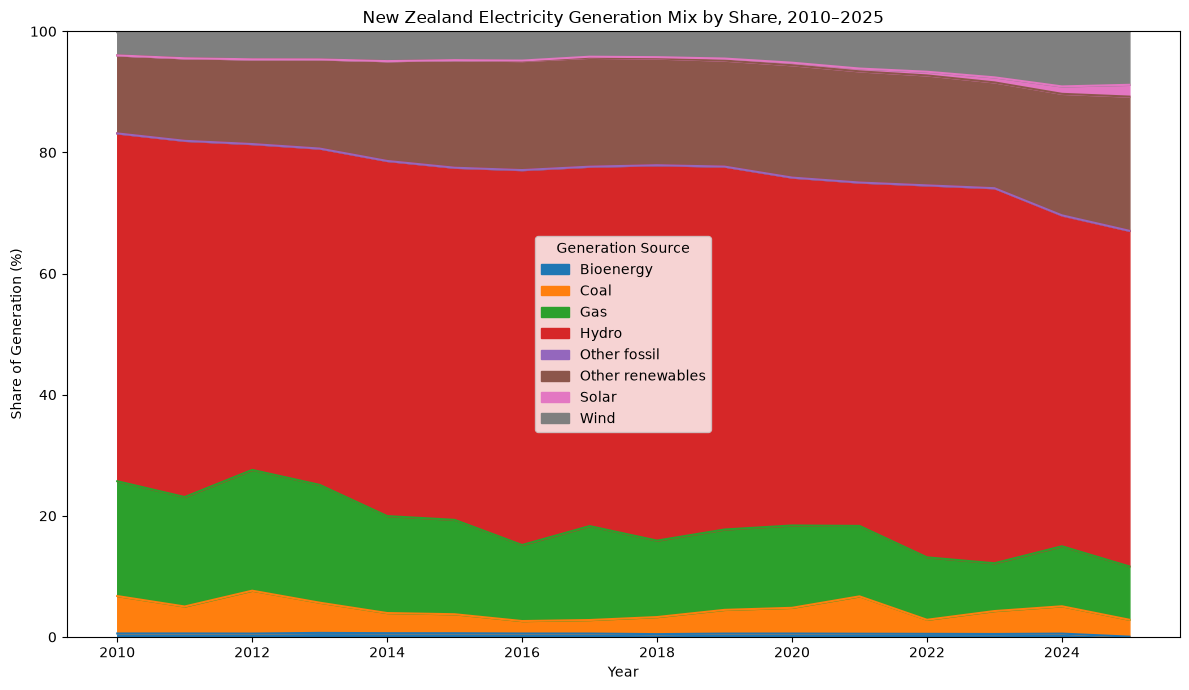

In [59]:
source_share_wide.plot(
    kind="area",
    stacked=True,
    figsize=(12, 7)
)

plt.xlabel("Year")
plt.ylabel("Share of Generation (%)")
plt.title("New Zealand Electricity Generation Mix by Share, 2010–2025")
plt.ylim(0, 100)
plt.legend(title="Generation Source")
plt.tight_layout()
plt.show()

#### Question How does New Zealand’s total electricity generation change from 2010 to 2025?

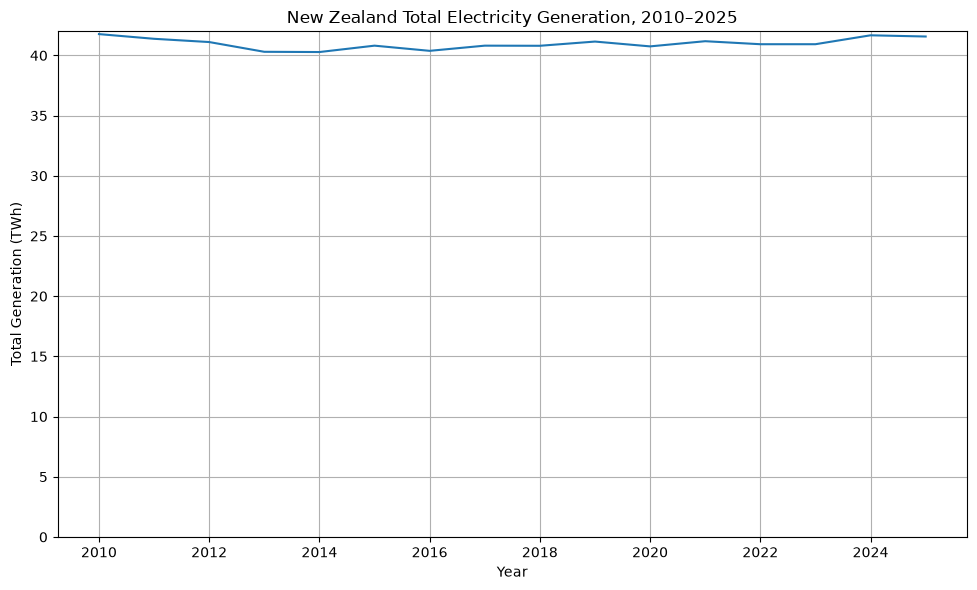

In [60]:
plt.figure(figsize=(10, 6))

plt.plot(
    categories_wide.index,
    categories_wide["Total generation"]
)

plt.xlabel("Year")
plt.ylabel("Total Generation (TWh)")
plt.title("New Zealand Total Electricity Generation, 2010–2025")
plt.grid(True)
plt.tight_layout()
plt.ylim(0, 42)
plt.show()

#### Effect of Y-Axis Scaling on Data Interpretation

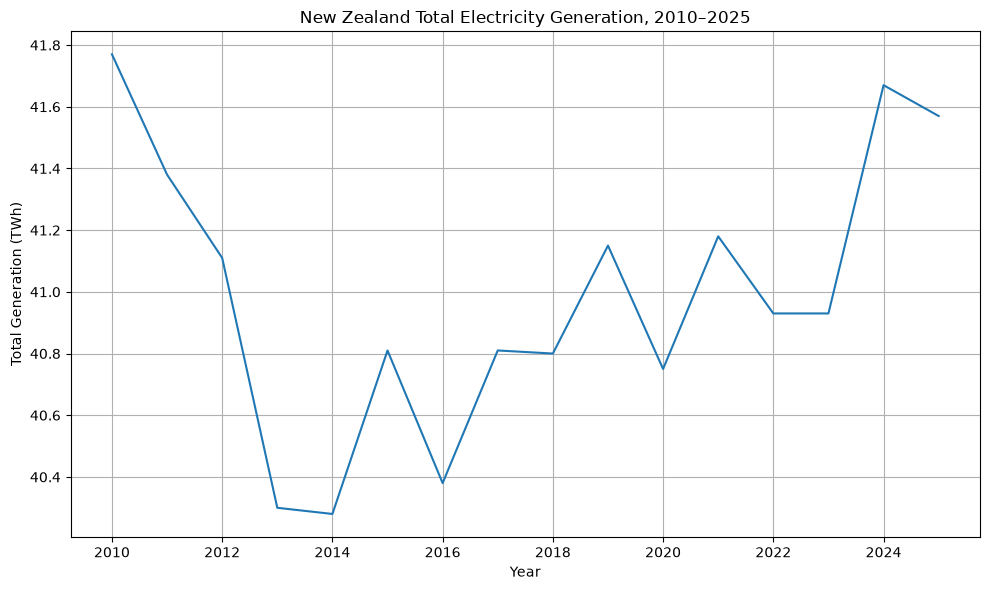

In [61]:
plt.figure(figsize=(10, 6))

plt.plot(
    categories_wide.index,
    categories_wide["Total generation"]
)

plt.xlabel("Year")
plt.ylabel("Total Generation (TWh)")
plt.title("New Zealand Total Electricity Generation, 2010–2025")
plt.grid(True)
plt.tight_layout()
plt.show()

How much did total generation change relative to the previous year's value?

Percentage Change=((Current Value−Previous Value)/ Previous Value)×100

In [62]:
categories_wide["generation_change_pct"] = (
    categories_wide["Total generation"].pct_change() * 100
)

In [63]:
categories_wide[["Total generation", "generation_change_pct"]]

series,Total generation,generation_change_pct
year,,
2010,41.77,NaN
2011,41.38,-0.933684
2012,41.11,-0.652489
2013,40.30,-1.970324
2014,40.28,-0.049628
2015,40.81,1.315789
2016,40.38,-1.053663
2017,40.81,1.064884
2018,40.80,-0.024504


In [64]:
categories_wide["generation_change_pct"].idxmin()


np.int32(2013)

In [65]:
categories_wide["generation_change_pct"].idxmax()

np.int32(2024)

In [66]:
categories_wide.loc[
    categories_wide["check"].abs().idxmax(),
    ["Renewables", "Fossil", "Total generation", "check"]
]

series
Renewables          33.21
Fossil               7.64
Total generation    40.81
check                0.04
Name: 2015, dtype: float64

In [67]:
category_monthly = (
    df[df["series"].isin(
        ["Renewables", "Fossil", "Total generation"]
    )]
    .pivot(
        index="date",
        columns="series",
        values="generation_twh"
    )
)

category_monthly["check"] = (
    category_monthly["Renewables"]
    + category_monthly["Fossil"]
    - category_monthly["Total generation"]
)

category_monthly.loc[
    category_monthly.index.year == 2015
]

series,Fossil,Renewables,Total generation,check
date,,,,
2015-01-01,0.66,2.65,3.31,0.00
2015-02-01,0.67,2.37,3.04,0.00
2015-03-01,0.89,2.42,3.31,0.00
2015-04-01,0.79,2.35,3.14,0.00
2015-05-01,0.50,2.99,3.48,0.01
2015-06-01,0.51,3.04,3.55,0.00
2015-07-01,0.70,3.06,3.76,0.00
2015-08-01,0.62,3.09,3.71,0.00
2015-09-01,0.64,2.84,3.47,0.01


In [68]:
pd.set_option("display.precision", 6)

category_monthly.loc[
    category_monthly.index.year == 2015,
    ["Fossil", "Renewables", "Total generation", "check"]
]

series,Fossil,Renewables,Total generation,check
date,,,,
2015-01-01,0.66,2.65,3.31,0.00
2015-02-01,0.67,2.37,3.04,0.00
2015-03-01,0.89,2.42,3.31,0.00
2015-04-01,0.79,2.35,3.14,0.00
2015-05-01,0.50,2.99,3.48,0.01
2015-06-01,0.51,3.04,3.55,0.00
2015-07-01,0.70,3.06,3.76,0.00
2015-08-01,0.62,3.09,3.71,0.00
2015-09-01,0.64,2.84,3.47,0.01


In [69]:
annual_gen_summary.columns

Index(['year', 'series', 'generation_twh', 'total_generation_twh',
       'annual_share_pct'],
      dtype='str')

In [70]:
annual_gen_summary.head(10)

,year,series,generation_twh,total_generation_twh,annual_share_pct
0,2010,Bioenergy,0.24,41.77,0.574575
1,2010,Coal,2.58,41.77,6.176682
2,2010,Gas,7.92,41.77,18.960977
3,2010,Hydro,23.99,41.77,57.433565
4,2010,Other fossil,0.00,41.77,0.000000
5,2010,Other renewables,5.38,41.77,12.880057
6,2010,Wind,1.60,41.77,3.830500
7,2011,Bioenergy,0.24,41.38,0.579990
8,2011,Coal,1.84,41.38,4.446593
9,2011,Gas,7.48,41.38,18.076365


In [71]:
annual_gen_summary.to_csv(
    "NZ_annual_generation_summary.csv",
    index=False
)

For New Zealand, Ember's methodology identifies Electricity Market Information (EMI), provided by the Electricity Authority Te Mana Hiko, as the source for monthly generation data

# Summary 

Summary and Key Findings

This project analysed New Zealand's electricity generation mix from 2010 to 2025 using monthly electricity generation data obtained from the Ember Energy API. The analysis examined changes in individual generation sources, renewable and fossil-fuel generation trends, and the overall composition of New Zealand's electricity generation.

Overall, annual electricity generation remained relatively stable over the study period, changing from 41.77 TWh in 2010 to 41.57 TWh in 2025, representing a decrease of approximately 0.48%. Despite this relatively small change in total generation, the composition of the electricity generation mix changed considerably.

The share of renewable electricity generation increased from 74.79% in 2010 to 88.41% in 2025, an increase of 13.61 percentage points. This growth was primarily driven by other renewable sources, which increased by 3.83 TWh, and wind generation, which increased by 2.07 TWh between 2010 and 2025. Solar generation reached 0.81 TWh in 2025. However, a direct comparison with 2010 was not possible because the dataset did not contain a solar generation observation for that year.

In contrast, fossil-fuel generation declined over the same period. Gas generation experienced the largest absolute decrease, falling by 4.26 TWh, while coal generation decreased by 1.42 TWh. Hydro remained New Zealand's largest individual electricity generation source, although its generation decreased slightly from 23.99 TWh in 2010 to 23.04 TWh in 2025. In 2025, hydro contributed approximately 55.42% of total electricity generation.

The statistical analysis identified a very strong negative linear association between renewable and fossil-fuel generation across the 16 annual observations (Pearson's r = −0.974, p-value = 2.22 × 10⁻¹⁰). However, this relationship should be interpreted cautiously because the analysis uses a limited number of annual observations, and renewable and fossil-fuel generation are components of total electricity generation. Therefore, the correlation indicates an association rather than establishing a causal relationship.

Data validation was also performed to check the consistency between aggregate renewable generation, fossil-fuel generation and total electricity generation. Small discrepancies were identified, with a maximum annual difference of 0.04 TWh in 2015. These differences were retained without manually adjusting the original data.

Overall, the findings demonstrate a substantial transition in New Zealand's electricity generation mix between 2010 and 2025. Renewable sources increased their contribution to electricity generation, while gas and coal generation declined, despite total annual electricity generation remaining relatively stable.

#### Link for Tableau dashboard

https://public.tableau.com/app/profile/shivani.singh2458/viz/NewZealandElectricityGenerationDashboard20102025/Dashboard1#1                